In [2]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from safetensors.torch import load_file

from stdev.pretrain.config import SDXL_DIRECTORY, VAE_DIRECTORY
from stdev.text_encoders.sdxl_text_encoder import SDXLTextEncoder
from stdev.upscalers.pretrain_large import UpscalerUNet, sample_high_resolution_latents
from stdev.vaes.flux_2_vae import Flux2VAE
from stdev.utils.image_tools import *

REPOSITORY_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file()
)
STAGE2_WEIGHTS_PATH = (
    REPOSITORY_ROOT / "pretrain_runs/stage2_v1/export/stage2_final_000054108_ema.safetensors"
)

DISTILL_CHECKPOINT_PATH = (
    REPOSITORY_ROOT / "/home/user/ML/STDev/sft_runs/flux2_v2/checkpoints/checkpoint_000020000.pt"
)

IMAGE_PATH = REPOSITORY_ROOT / "datasets/4klsdb_subset/hr/103430.png"
OUTPUT_DIRECTORY = REPOSITORY_ROOT / "local_samples/inference"
PROMPT = "ultra detailed. A duck."
SEED = 0
DEVICE = torch.device("cuda")

for checkpoint_path in (STAGE2_WEIGHTS_PATH, DISTILL_CHECKPOINT_PATH):
    if not checkpoint_path.is_file():
        raise FileNotFoundError(checkpoint_path)
    print(
        f"{checkpoint_path.relative_to(REPOSITORY_ROOT)}: {checkpoint_path.stat().st_size / 2**30:.2f} GiB"
    )

torch.backends.cudnn.benchmark = True

pretrain_runs/stage2_v1/export/stage2_final_000054108_ema.safetensors: 1.68 GiB
sft_runs/flux2_v2/checkpoints/checkpoint_000020000.pt: 6.72 GiB


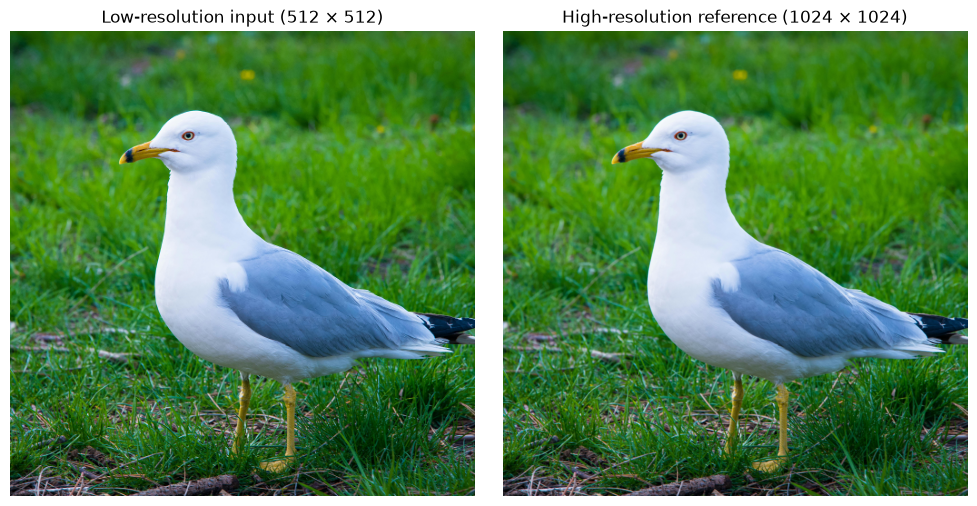

In [3]:
def load_image_pair(
    image_path: Path, high_resolution_size: int = 1024
) -> tuple[np.ndarray, np.ndarray]:
    """
    returns:
        image_high: [H, W, 3], channel_order: RGB, pixel_values: [0...255], dtype: uint8
        image_low: [H / 2, W / 2, 3], channel_order: RGB, pixel_values: [0...255], dtype: uint8
    """
    image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Could not read {image_path}")
    height, width = image.shape[:2]
    crop_size = min(height, width)
    top = (height - crop_size) // 2
    left = (width - crop_size) // 2
    image = image[top : top + crop_size, left : left + crop_size]
    image_high = cv2.resize(
        image, (high_resolution_size, high_resolution_size), interpolation=cv2.INTER_AREA
    )
    image_low = cv2.resize(
        image_high, (high_resolution_size // 2,) * 2, interpolation=cv2.INTER_CUBIC
    )
    return (
        cv2.cvtColor(image_high, cv2.COLOR_BGR2RGB),
        cv2.cvtColor(image_low, cv2.COLOR_BGR2RGB),
    )


image_high, image_low = load_image_pair(IMAGE_PATH)
figure, axes = plt.subplots(1, 2, figsize=(10, 5))
for axis, image, title in zip(
    axes,
    (image_low, image_high),
    ("Low-resolution input (512 × 512)", "High-resolution reference (1024 × 1024)"),
    strict=True,
):
    axis.imshow(image)
    axis.set_title(title)
    axis.axis("off")
figure.tight_layout()
plt.show()

In [4]:
vae = Flux2VAE(str(VAE_DIRECTORY), device=DEVICE, dtype=torch.bfloat16)
text_encoder = SDXLTextEncoder(str(SDXL_DIRECTORY), device=DEVICE, dtype=torch.float16)
text_embedding = text_encoder.encode_text_batch([PROMPT]).float().mean(dim=1)

The config attributes {'force_upcast': True} were passed to AutoencoderKLFlux2, but are not expected and will be ignored. Please verify your config.json configuration file.
There are modules in AutoencoderKLFlux2 that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

In [5]:
latents_lr = vae.encode(np_to_torch(image_low))

In [9]:
def load_distilled_model(checkpoint_path: Path) -> UpscalerUNet:
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    model = UpscalerUNet()
    ema_weights = {
        name: ema_parameter
        for (name, _), ema_parameter in zip(
            model.named_parameters(), checkpoint["ema"], strict=True
        )
    }
    model.load_state_dict(checkpoint["model"])
    return model.to(DEVICE, torch.bfloat16).eval().requires_grad_(False)


model = load_distilled_model(DISTILL_CHECKPOINT_PATH)

In [10]:
batch_size = latents_lr.shape[0]
high_frequency_features = torch.ones(batch_size, 4, device=DEVICE)
high_frequency_mask = torch.ones(batch_size, 4, dtype=torch.bool, device=DEVICE)
text_mask = torch.ones(batch_size, dtype=torch.bool, device=DEVICE)

current_latents = latents_lr.clone()

for i in range(2):
    noise_generator = torch.Generator(device=DEVICE).manual_seed(SEED)
    noise = torch.randn(
        (
            1,
            current_latents.shape[1],
            current_latents.shape[-2] * 2,
            current_latents.shape[-1] * 2,
        ),
        generator=noise_generator,
        device=DEVICE,
    )

    current_latents = sample_high_resolution_latents(
        model,
        current_latents,
        text_embedding,
        text_mask,
        high_frequency_features,
        high_frequency_mask,
        num_steps=8,
        sigma_shift=2.0,
        noise=noise,
    )

    # current_image = vae.decode(current_latents)
    # current_image = torch_to_np(current_image)
    # cv2.imwrite(f"samples/chain_{i}.png", np_to_cv2(current_image))
    # current_image = cv2.resize(current_image, (512, 512), interpolation=cv2.INTER_CUBIC)
    # current_image = np_to_torch(current_image)
    # current_latents = vae.encode(current_image)

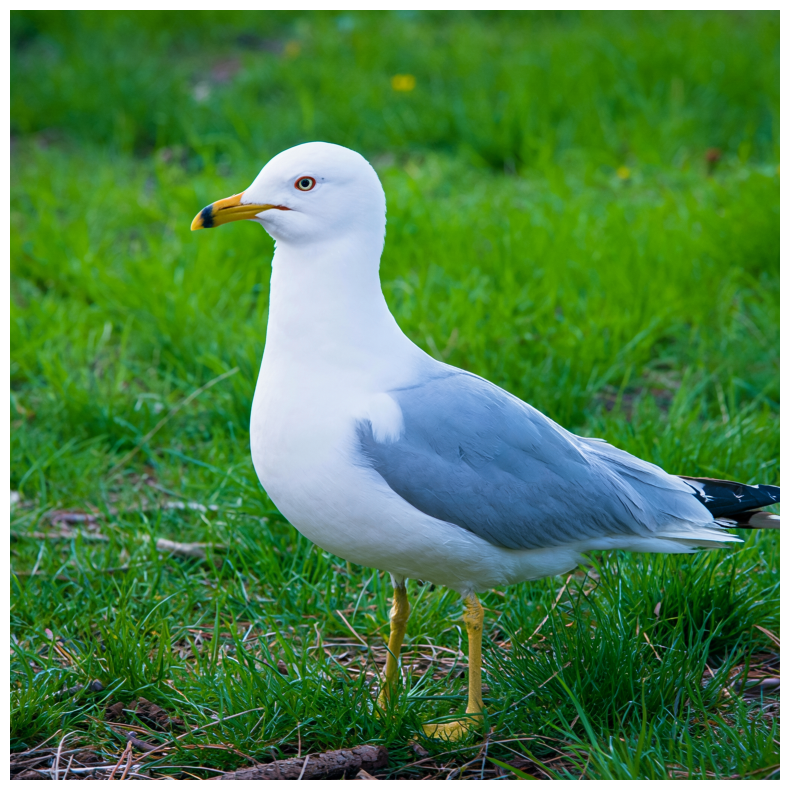

True

In [11]:
image_hr = vae.decode(current_latents)
image_hr = torch_to_np(image_hr)

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
ax.imshow(image_hr)

ax.axis("off")
plt.show()

cv2.imwrite("samples/sft_try_2.png", np_to_cv2(image_hr))